# Integrador e desempenho

Onde vai o tempo no severe slug e as alavancas que o reduzem sem perder o ciclo; o lado direito compilado com Jacobiana exata, nos casos de severe slug, do capítulo 10 e no gas lift.

Issues ilustradas (índice em [docs/issues/INDEX.md](../../docs/issues/INDEX.md)):
- [032](../../docs/issues/032-bdf-implicito-proprio.md)
- [033](../../docs/issues/033-slow-exit-regressao.md)
- [034](../../docs/issues/034-tolerancia-por-faixa.md)
- [035](../../docs/issues/035-config-rapida.md)
- [036](../../docs/issues/036-lado-direito-jax.md)
- [037](../../docs/issues/037-tangentes-nan.md)
- [038](../../docs/issues/038-derivadas-beggs-brill.md)

*Nenhuma simulação corre aqui: as corridas vêm de `notebooks/data` (dados históricos, 2026-10)
e dos lotes `batches/*.json` (`mfsim batch`); o notebook só lê e desenha.*

In [1]:
import numpy as np, matplotlib.pyplot as plt, os, json, warnings

warnings.filterwarnings("ignore")
from mfsim.fluid import Fluid
from mfsim.runs import find_run, load_run

fluid = Fluid(rhoL0=900.0, rhoG0=1.2, muL=2e-3, muG=1.8e-5, gammaL=100.0, gammaG=1.05, P0=1e5, sigma=0.05)
D = 0.05
A = np.pi * D**2 / 4
P_out = 4.0
qL = 0.3 * 900 * A
qG = 0.1 * fluid.rhoG((P_out + 1) * 1e5) * A


def datafile(fname):
    """Caminho de uma corrida gravada (notebooks/data ou runs/), ou None se não existir."""
    try:
        return find_run(fname)
    except FileNotFoundError:
        print("trajetória não encontrada:", fname)
        return None


def blowdowns(T_, P_in, min_gap=200.0):
    """Instantes dos blowdowns: mínimos locais da pressão na entrada abaixo de 30 % da
    faixa (separados por pelo menos min_gap s; um blowdown tem mínimos secundários nos
    100 s seguintes). Mais robusto do que contar picos de vazão."""
    lvl = P_in.min() + 0.3 * (P_in.max() - P_in.min())
    low = P_in < lvl
    out = []
    i = 0
    while i < T_.size:
        if low[i]:
            j = i
            while j < T_.size and low[j]:
                j += 1
            k = i + int(np.argmin(P_in[i:j]))
            if not out or T_[k] - out[-1] > min_gap:
                out.append(T_[k])
            i = j
        else:
            i += 1
    return np.array(out)


def cycle_stats(T_, P_in, q_out):
    """(número de blowdowns, período médio entre blowdowns [s], pico máximo de líquido após t = 100 s)."""
    tb = blowdowns(T_, P_in)
    per = float(np.mean(np.diff(tb))) if tb.size > 1 else np.nan
    return tb.size, per, float(q_out[T_ > 100].max())


def load_blocked_run(f):
    """Corrida gravada (partida bloqueada ou linha fechada) pelo carregador único
    `mfsim.runs.load_run` (reconstrói o caso do `meta` com os defaults deste notebook, ou de
    `case_json` nas corridas novas) e os balanços de massa; era uma cópia desta lógica."""
    r = load_run(f)
    return dict(
        meta=r.meta,
        case=r.case,
        model=r.model,
        res=r.res,
        T=r.T,
        p=r.pipe(0),
        ib=r.ib,  # célula no início do joelho
        balL=r.balance("L"),
        balG=r.balance("G"),
        acc=r.acc,  # integral BDF-consistente dos fluxos de contorno
        p_last=r.p_last,  # duto que termina no separador (rede: o último)
        aG_riser_base=r.aG_riser_base(),
    )

## Aceleração: onde vai o tempo e como reduzi-lo sem perder o ciclo

Na malha grossa de referência (arco, mistura, conservativa, ν = 0.01·c·h): 14 ms
por passo, 23.6 avaliações do lado direito por passo (metade em Jacobianas
coloridas, 25 cores) e 92 % dos passos nas fases com gás no riser (*blowdown* e
reenchimento, h ≈ 14 ms), onde o tampão de líquido e o bolsão de gás "tocam"
acusticamente. O Newton converge devagar (≈ 6 iterações) por não-suavidade dos
fechamentos e chaveamentos, não por Jacobiana ruim (Jacobiana nova a cada passo e
passos de diferenças finitas diferentes não mudam nada). GPU não ajuda: o problema
tem ~100–200 estados e é limitado por latência de chamadas numpy, não por vazão.

Alavancas testadas em janelas de reinício na fase cara (800–830 s, com as
sondagens `archive/scratch_2026-10/py/restart_ring.py` e `restart_probe.py`):

| alavanca | passos na janela | observação |
|---|---|---|
| referência (ν = 0.01) | 5140 | — |
| ν = 0.05 | 3729 | mesmo estado final |
| orçamento de Newton 12 → 20 iterações | 1946 (janela de 20 s: 2779 → 1946) | menos rejeições e Jacobianas |
| ν = 0.05 + Newton 20 | 1636 (20 s) | −41 % |
| + tolerância absoluta nas vazões 0.03 kg/s e em P 0.1 bar | 1311 (30 s, contra 3068) | o toque de ±0.03 kg/s deixa de ser resolvido; P final desvia 0.03 bar |
| + tolerância absoluta 0.05 kg/s e 0.2 bar | 993 (30 s) | −68 %; desvio 0.04 bar |
| BDF1, relaxação 0.5/0.005 s, γL = 30, rtol só em P, Jacobiana a cada passo | sem ganho ou pior | |

**Lado direito compilado (JAX).** `mfsim/compiled.py` executa o mesmo código numpy
(fechamentos, esquema escalonado conservativo, limitador, relaxação, viscosidade
artificial, contornos tipo B) com o backend JAX injetado — até à reorganização
`jaxrhs.py` era uma reescrita — e reproduz o lado direito numpy a 1e−13. Com `jit`
a avaliação cai de 0.43 para 0.08 ms e a Jacobiana exata por diferenciação
automática (`jax.jacfwd`) custa 0.9 ms contra 10.7 ms das diferenças finitas
coloridas; o integrador recebe a Jacobiana pela opção `jac_fun`. A Jacobiana
exata não reduz as iterações de Newton (a dificuldade é a não-suavidade), mas o
custo por passo cai 4 a 6×. Duas armadilhas da diferenciação automática: raízes
quadradas de quantidades que se anulam (0 × ∞ = NaN na derivada; resolvido com
*double where*) e derivadas em quinas (clips em α = 0, chaveamentos em q = 0),
onde diferenças finitas e AD divergem legitimamente.

Abaixo, as simulações completas com essas configurações comparadas à referência
e à malha fina.

In [2]:
runs_fast = {}
for tag, fname in (
    ("referência (ν = 0.01)", "severe_slug_blocked_conservative_arc_av.npz"),
    ("ν = 0.05 + Newton 20", "severe_slug_blocked_conservative_arc_av05.npz"),
    ("+ atol 0.03 kg/s, 0.1 bar", "severe_slug_blocked_conservative_arc_fast1.npz"),
    ("+ atol 0.05 kg/s, 0.2 bar", "severe_slug_blocked_conservative_arc_fast2.npz"),
    ("atol 0.03/0.1, lado direito JAX", "severe_slug_blocked_conservative_arc_fast1_jax.npz"),
    ("malha fina 30/10 (ν = 0.01)", "severe_slug_blocked_conservative_arc_fine_av.npz"),
    ("malha fina, atol 0.03/0.1, JAX", "severe_slug_blocked_conservative_arc_fine_fast1_jax.npz"),
):
    f = datafile(fname)
    if f is None:
        print("trajetória não encontrada:", f)
        continue
    runs_fast[tag] = load_blocked_run(f)

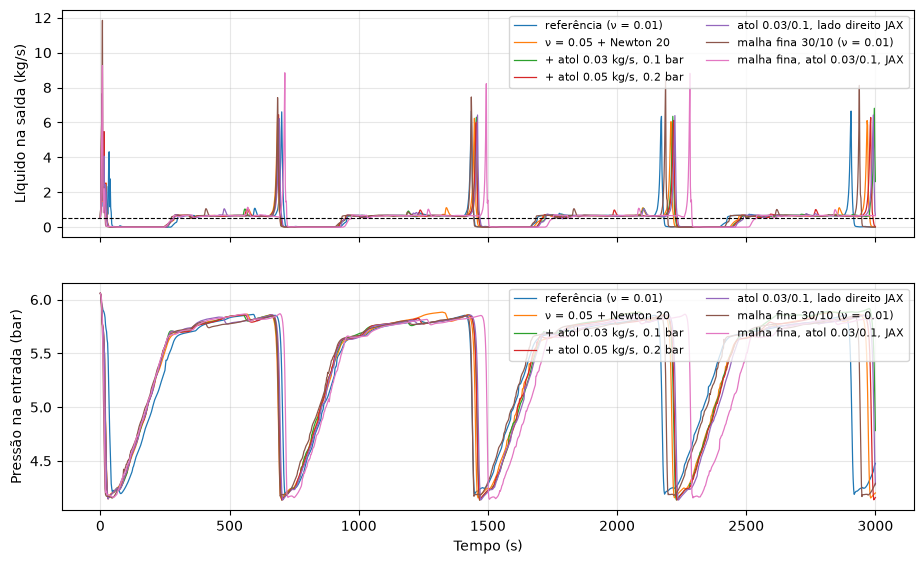

configuração                     passos     CPU blowdowns  período  pico máx   P_in (bar)  erro massa L
referência (ν = 0.01)             85653    20 min         5    710 s    6.7 kg/s  4.19–5.86     -5.1e-06 kg
ν = 0.05 + Newton 20              59236    14 min         5    738 s    6.4 kg/s  4.15–5.88     -2.0e-06 kg
+ atol 0.03 kg/s, 0.1 bar         23172     5 min         4    733 s    6.8 kg/s  4.13–5.92     -4.6e-04 kg
+ atol 0.05 kg/s, 0.2 bar         21798     5 min         5    741 s    6.4 kg/s  4.14–5.86     -9.7e-04 kg
atol 0.03/0.1, lado direito JAX    22618     1 min         5    742 s    6.4 kg/s  4.14–5.86     -2.8e-04 kg
malha fina 30/10 (ν = 0.01)      201553    58 min         5    726 s    8.6 kg/s  4.17–5.85     -9.5e-06 kg
malha fina, atol 0.03/0.1, JAX    39033     2 min         4    747 s    8.8 kg/s  4.14–5.87     -3.6e-04 kg


In [3]:
if runs_fast:
    fig, axes = plt.subplots(2, 1, figsize=(11, 6.5), sharex=True)
    for k, (tag, r) in enumerate(runs_fast.items()):
        T_, p_ = r["T"], r["p"]
        axes[0].plot(T_, p_["out"]["qL"][-1], lw=0.9, label=tag)
        axes[1].plot(T_, p_["out"]["P_bar"][1], lw=0.9, label=tag)
    axes[0].axhline(qL, color="k", ls="--", lw=0.8)
    axes[0].set_ylabel("Líquido na saída (kg/s)")
    axes[1].set_ylabel("Pressão na entrada (bar)")
    axes[1].set_xlabel("Tempo (s)")
    for ax in axes:
        ax.grid(alpha=0.3)
        ax.legend(fontsize=8, loc="upper right", ncol=2)
    plt.show()
    print(
        f"{'configuração':30s} {'passos':>8s} {'CPU':>7s} {'blowdowns':>9s} {'período':>8s} {'pico máx':>9s} {'P_in (bar)':>12s} {'erro massa L':>13s}"
    )
    for tag, r in runs_fast.items():
        T_, q_ = r["T"], r["p"]["out"]["qL"][-1]
        nb_, per, qmax = cycle_stats(T_, r["p"]["out"]["P_bar"][1], q_)
        massL, _, _ = r["balL"]
        eL = (massL[-1] - massL[0] - r["acc"][0, -1]) if r["acc"] is not None else np.nan
        P1 = r["p"]["out"]["P_bar"][1][T_ > 100]
        print(
            f"{tag:30s} {r['meta']['n_steps']:8d} {r['meta']['cpu']/60:5.0f} min {nb_:9d} {per:6.0f} s {qmax:6.1f} kg/s {P1.min():5.2f}–{P1.max():4.2f} {eL:+12.1e} kg"
        )

## Casos do capítulo 10 com o BDF próprio: numpy contra JAX (corridas `runs/issues/<caso>_implicit|_jax`)
A mesma simulação com o lado direito em numpy (Jacobiana por diferenças finitas coloridas) e
compilado (`backend = jax`, Jacobiana exata por diferenciação automática). As sequências de passos
podem diferir porque a Jacobiana muda o Newton; os estados coincidem dentro da tolerância, e a
diferença pontual cresce nos casos com ciclos-limite (picos deslocados no tempo).

In [4]:
print(
    f"{'caso':10s} {'passos numpy':>12s} {'passos JAX':>10s} {'CPU numpy':>10s} {'CPU JAX':>8s} {'dif. máx. relativa':>18s}"
)
for key in ("10_1_1", "10_1_4", "10_3_1", "10_3_2b", "10_3_3"):
    rn, rj = load_run(f"issues/{key}_implicit"), load_run(f"issues/{key}_jax")
    n = min(rn.X.shape[1], rj.X.shape[1])
    scale = np.max(np.abs(rn.X), axis=1) + 1e-12
    d = np.max(np.abs(rn.X[:, :n] - rj.X[:, :n]) / scale[:, None])
    print(
        f"{key:10s} {rn.info['n_steps']:12d} {rj.info['n_steps']:10d} {rn.info['cpu']:9.2f}s {rj.info['cpu']:7.2f}s {d:18.1e}"
    )

caso       passos numpy passos JAX  CPU numpy  CPU JAX dif. máx. relativa
10_1_1              168        168      0.81s    0.35s            9.9e-07
10_1_4              526        526      7.59s    2.74s            7.7e-04
10_3_1              481        418      3.09s    0.85s            1.0e-01
10_3_2b             342        347      8.69s    1.68s            2.2e-02
10_3_3               78         78      1.00s    1.55s            2.1e-05


## Gas lift com intermitência forte: numpy contra JAX (corridas `runs/issues/gas_lift_12` e `gas_lift_12_jax`)

passos: numpy 2897, JAX 2914 | CPU: numpy 72.5 s, JAX 8.5 s
diferença máxima relativa dos estados numpy x JAX: 3.7e-01


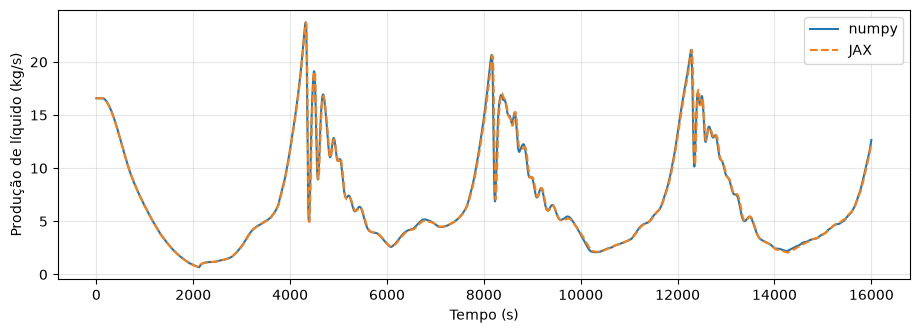

In [5]:
rn, rj = load_run("issues/gas_lift_12"), load_run("issues/gas_lift_12_jax")
res_n, res_j = rn.res, rj.res
n = min(res_n.X.shape[1], res_j.X.shape[1])
scale = np.max(np.abs(res_n.X), axis=1) + 1e-12
print(
    f"passos: numpy {rn.info['n_steps']}, JAX {rj.info['n_steps']} | CPU: numpy {rn.info['cpu']:.1f} s, JAX {rj.info['cpu']:.1f} s"
)
print(
    f"diferença máxima relativa dos estados numpy x JAX: {np.max(np.abs(res_n.X[:, :n] - res_j.X[:, :n]) / scale[:, None]):.1e}"
)
fig, ax = plt.subplots(figsize=(11, 3.5))
ax.plot(res_n.T, res_n.elements["valves"][4]["qL"], label="numpy")
ax.plot(res_j.T, res_j.elements["valves"][4]["qL"], "--", label="JAX")
ax.set_xlabel("Tempo (s)")
ax.set_ylabel("Produção de líquido (kg/s)")
ax.legend()
ax.grid(alpha=0.3)
plt.show()